<a href="https://colab.research.google.com/github/YuncheKim/2026_sundaesu/blob/main/1031_%EC%84%A0%EB%8C%80%EC%88%98_%EC%B6%94%EA%B0%80_ipynb%EC%9D%98_%EC%82%AC%EB%B3%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000
LEN = 100

In [4]:
def draw_axis(ax):
    ax.axhline(0, color='black', alpha=0.3)
    ax.axvline(0, color='black', alpha=0.3)
    ax.set_xlim(-INF, INF)
    ax.set_ylim(-INF, INF)
    ax.set_aspect('equal')

In [5]:
def draw_rectangle(ax, p1, p2, p3, p4, color='tab:blue', zorder=1):
    my_polygon = Polygon([p1, p2, p3, p4], facecolor=color, edgecolor=color, zorder=zorder)
    ax.add_patch(my_polygon)


In [6]:
def transform(m, p):
  hp = np.array([p[0], p[1], 1.0])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])

In [7]:
def translate(p, dx, dy):
    m = np.array([[1.0, 0.0, dx],
                  [0.0, 1.0, dy],
                  [0.0, 0.0, 1.0]])
    return transform(m, p)

In [8]:
def rotate(p, theta):
    m = np.array([[np.cos(theta), -np.sin(theta), 0.0],
                  [np.sin(theta),  np.cos(theta), 0.0],
                  [0.0,            0.0,           1.0]])
    return transform(m, p)

In [9]:
def scale(p, sx, sy):
    m = np.array([[sx,  0.0, 0.0],
                  [0.0, sy,  0.0],
                  [0.0, 0.0, 1.0]])
    return transform(m, p)

In [10]:
def shear_x(p, sx):
    m = np.array([[1.0, sx,  0.0],
                  [0.0, 1.0, 0.0],
                  [0.0, 0.0, 1.0]])
    return transform(m, p)

In [11]:
def shear_y(p, sy):
    m = np.array([[1.0, 0.0, 0.0],
                  [sy,  1.0, 0.0],
                  [0.0, 0.0, 1.0]])
    return transform(m, p)


In [12]:
def reflect_x(p):
    m = np.array([[1.0,  0.0, 0.0],
                  [0.0, -1.0, 0.0],
                  [0.0,  0.0, 1.0]])
    return transform(m, p)

In [13]:
def reflect_y(p):
    m = np.array([[-1.0, 0.0, 0.0],
                  [ 0.0, 1.0, 0.0],
                  [ 0.0, 0.0, 1.0]])
    return transform(m, p)

In [14]:
def reflect_origin(p):
    m = np.array([[-1.0,  0.0, 0.0],
                  [ 0.0, -1.0, 0.0],
                  [ 0.0,  0.0, 1.0]])
    return transform(m, p)

In [15]:
def reflect_yx(p):
    m = np.array([[0.0, 1.0, 0.0],
                  [1.0, 0.0, 0.0],
                  [0.0, 0.0, 1.0]])
    return transform(m, p)

In [58]:

def apply_all(points, f, *args):
    return [f(p, *args) for p in points]


In [232]:
def draw_face(ax, p1, p2, p3, p4):
    q = [p1, p2, p3, p4]
    q = apply_all(q, translate, -LEN/2, -LEN/2)
    q = apply_all(q, scale, 3.5, 3.5)
    q = apply_all(q, rotate, np.pi/4)
    q = apply_all(q, translate, 0, 5*LEN/2)
    draw_rectangle(ax, *q, color='wheat', zorder=4)

    w = [p1, p2, p3, p4]
    w = apply_all(w, translate, -LEN/2, -LEN/2)
    w = apply_all(w, scale, 5, 5)
    draw_rectangle(ax, *w, color='wheat', zorder=4)

    e= [p1, p2, p3, p4]
    e = apply_all(e, translate, -LEN/2, -LEN/2)
    e = apply_all(e, scale, 3.5, 3.5)
    e = apply_all(e, rotate, np.pi/4)
    e = apply_all(e, translate, 0, -5*LEN/2)
    draw_rectangle(ax, *e, color='wheat', zorder=4)


In [236]:
def right_lip(ax,p1, p2, p3, p4):
    q = [p1, p2, p3, p4]
    q = apply_all(q, translate, -LEN/2, -LEN/2)
    q = apply_all(q, scale, 3, 0.2)
    q = apply_all(q, rotate, np.pi/4)
    q = apply_all(q, translate, 1*LEN, -7*LEN/2)
    draw_rectangle(ax, *q, color='rosybrown', zorder=4)
def left_lip(ax,p1, p2, p3, p4):
    q = [p1, p2, p3, p4]
    q = apply_all(q, translate, -LEN/2, -LEN/2)
    q = apply_all(q, scale, 3, 0.2)
    q = apply_all(q, rotate, np.pi/-4)
    q = apply_all(q, translate, -1*LEN, -7*LEN/2)
    draw_rectangle(ax, *q, color='rosybrown', zorder=4)



In [163]:
def left_hair(ax,p1, p2, p3, p4):
    q = [p1, p2, p3, p4]
    q = apply_all(q, translate, -LEN/2, -LEN/2)
    q = apply_all(q, scale, 2, 4)
    q = apply_all(q, rotate, np.pi/-4)
    q = apply_all(q, translate, -0.5*LEN, 9.5*LEN/2)
    q = apply_all(q, shear_x, -0.25)
    q = apply_all(q, shear_y, 0.7)
    draw_rectangle(ax, *q, color='black', zorder=4)

def right_hair(ax,p1, p2, p3, p4):
    q = [p1, p2, p3, p4]
    q = apply_all(q, translate, -LEN/2, -LEN/2)
    q = apply_all(q, scale, 4, 2)
    q = apply_all(q, rotate, np.pi/-4)
    q = apply_all(q, translate, 0.5*LEN, 9.5*LEN/2)
    q = apply_all(q, shear_x, 0.25)
    q = apply_all(q, shear_y, -0.7)
    draw_rectangle(ax, *q, color='black', zorder=4)

In [230]:

def left_nose(ax,p1, p2, p3, p4):
    q = [p1, p2, p3, p4]
    q = apply_all(q, translate, -LEN/2, -LEN/2)
    q = apply_all(q, scale, 0.1, 1)
    q = apply_all(q, translate, -0.3*LEN, 1*LEN/2)
    draw_rectangle(ax, *q, color='saddlebrown', zorder=4)
def right_nose(ax,p1, p2, p3, p4):
    q = [p1, p2, p3, p4]
    q = apply_all(q, translate, -LEN/2, -LEN/2)
    q = apply_all(q, scale, 0.1, 1)
    q = apply_all(q, translate, 0.3*LEN, 1*LEN/2)
    draw_rectangle(ax, *q, color='saddlebrown', zorder=4)

def middle_somthing(ax,p1, p2, p3, p4):
    q = [p1, p2, p3, p4]
    q = apply_all(q, translate, -LEN/2, -LEN/2)
    q = apply_all(q, scale, 0.1, 4)
    q = apply_all(q, translate, 0, -5*LEN/2)
    draw_rectangle(ax, *q, color='saddlebrown', zorder=4)

In [238]:
def left_brow(ax,p1, p2, p3, p4):
    q = [p1, p2, p3, p4]
    q = apply_all(q, translate, -LEN/2, -LEN/2)
    q = apply_all(q, scale, 1, 0.1)
    q = apply_all(q, translate, -1.1*LEN, 4.5*LEN/2)
    draw_rectangle(ax, *q, color='black', zorder=4)
def right_brow(ax,p1, p2, p3, p4):
    q = [p1, p2, p3, p4]
    q = apply_all(q, translate, -LEN/2, -LEN/2)
    q = apply_all(q, scale, 1, 0.1)
    q = apply_all(q, translate, 1.1*LEN, 4.5*LEN/2)
    draw_rectangle(ax, *q, color='black', zorder=4)

def left_eye(ax,p1, p2, p3, p4):
    q = [p1, p2, p3, p4]
    q = apply_all(q, translate, -LEN/2, -LEN/2)
    q = apply_all(q, scale, 0.8, 0.05)
    q = apply_all(q, translate, -1.1*LEN, 3.8*LEN/2)
    draw_rectangle(ax, *q, color='black', zorder=4)
def right_eye(ax,p1, p2, p3, p4):
    q = [p1, p2, p3, p4]
    q = apply_all(q, translate, -LEN/2, -LEN/2)
    q = apply_all(q, scale, 0.8, 0.05)
    q = apply_all(q, translate, 1.1*LEN, 3.8*LEN/2)
    draw_rectangle(ax, *q, color='black', zorder=4)


In [216]:
def draw_circle(ax, cx, cy, r, color='black', zorder=5):
    t = np.linspace(0, 2*np.pi, 100)
    points = [(cx + r*np.cos(a), cy + r*np.sin(a)) for a in t]
    ax.add_patch(Polygon(points, facecolor=color, edgecolor=color, zorder=zorder))

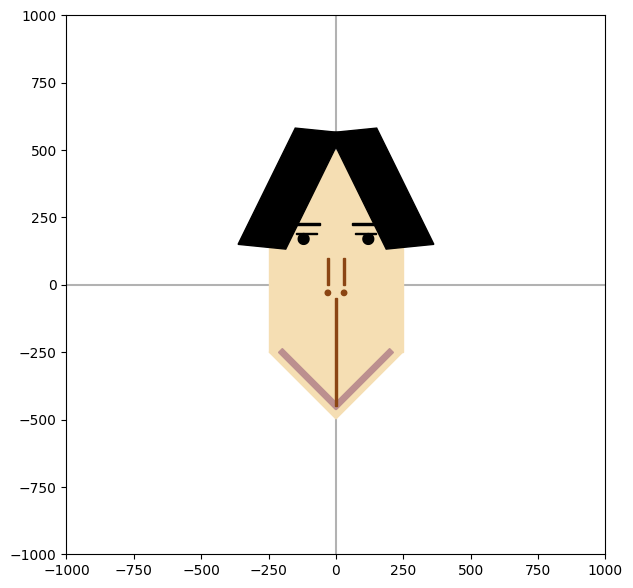

In [241]:
def draw_object(ax):
    p1 = np.array([0, 0])
    p2 = np.array([LEN, 0])
    p3 = np.array([LEN, LEN])
    p4 = np.array([0, LEN])

    draw_face(ax, p1, p2, p3, p4)
    right_lip(ax, p1, p2, p3, p4)
    left_lip(ax, p1, p2, p3, p4)
    left_hair(ax, p1, p2, p3, p4)
    right_hair(ax, p1, p2, p3, p4)
    left_nose(ax, p1, p2, p3, p4)
    right_nose(ax, p1, p2, p3, p4)
    middle_somthing(ax, p1, p2, p3, p4)
    left_brow(ax, p1, p2, p3, p4)
    right_brow(ax, p1, p2, p3, p4)
    left_eye(ax, p1, p2, p3, p4)
    right_eye(ax, p1, p2, p3, p4)
    draw_circle(ax, -1.2*LEN, 1.7*LEN, 0.2*LEN)
    draw_circle(ax,  1.2*LEN, 1.7*LEN, 0.2*LEN)
    draw_circle(ax, -0.3*LEN, -0.3*LEN, 0.1*LEN, color='saddlebrown')
    draw_circle(ax,  0.3*LEN, -0.3*LEN, 0.1*LEN, color='saddlebrown')

fig, ax = plt.subplots(figsize=(7, 7))
draw_axis(ax)
draw_object(ax)
plt.show()